In [2]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [3]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [4]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)



species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
    )
)

In [5]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=1000):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, 0)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=1000)

In [34]:
sub_neptune = Planet(
    surface_temperature=3000,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [35]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyHF_withsol = InteriorAtmosphere(species_ideal)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
miauw = model_ideal_varyHF_withsol.output

# Write the complete solution to Excel
miauw.to_excel("SUBNEPTUNE_IDEALCORTT")

# Write the data to a pickle file with dataframes
miauw.to_pickle("SUBNEPTUNE_IDEALCORTT")

[12:44:21 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[12:44:21 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:44:21 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '1.0 CO2_g = 0.5 O2_g + 1.0 CO_g',
 2: '2.0 H2_g + 1.0 CO2_g = 1.0 O2_g + 1.0 CH4_g'}
[12:44:21 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[12:44:21 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[12:44:21 - atmodeller.classes             - INFO     ] - Solver steps (max) = 52
[12:44:21 - atmodeller.output              - INFO     ] - Writing output to excel
[12:44:21 - 

In [31]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("SUBNEPTUNE_REALCORTT")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("SUBNEPTUNE_REALCORTT")

[12:43:51 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[12:43:51 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:43:51 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '1.0 CO2_g = 0.5 O2_g + 1.0 CO_g',
 2: '2.0 H2_g + 1.0 CO2_g = 1.0 O2_g + 1.0 CH4_g'}
[12:43:51 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[12:43:52 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[12:43:52 - atmodeller.classes             - INFO     ] - Solver steps (max) = 79
[12:43:52 - atmodeller.output              - INFO   

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib import rcParams

def set_presentation_style():
    plt.rcdefaults()
    rcParams["font.family"] = "sans-serif"
    rcParams["font.size"] = 15
    rcParams["axes.labelsize"] = 18
    rcParams["axes.titlesize"] = 20
    rcParams["legend.fontsize"] = 15

def set_paper_style():
    plt.rcdefaults()
    rcParams["font.family"] = "serif"
    rcParams["font.size"] = 9
    rcParams["axes.labelsize"] = 10
    rcParams["axes.titlesize"] = 10
    rcParams["legend.fontsize"] = 8

# Color palettes
palette_T = get_cmap("Set2")(np.linspace(0,1,3))     # 3 temperatures
palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3)) # 3 fO2 states


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_52368/2540691729.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_T = get_cmap("Set2")(np.linspace(0,1,3))     # 3 temperatures
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_52368/2540691729.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3)) # 3 fO2 states



Starting batch plot generation...

Creating plot for: Elemental Budget Distribution (Real Gas)
Reading from: SUBNEPTUNE_REALCORT.xlsx

✓ Successfully saved: AASUBA.png
Displaying plot for Elemental Budget Distribution (Real Gas)...


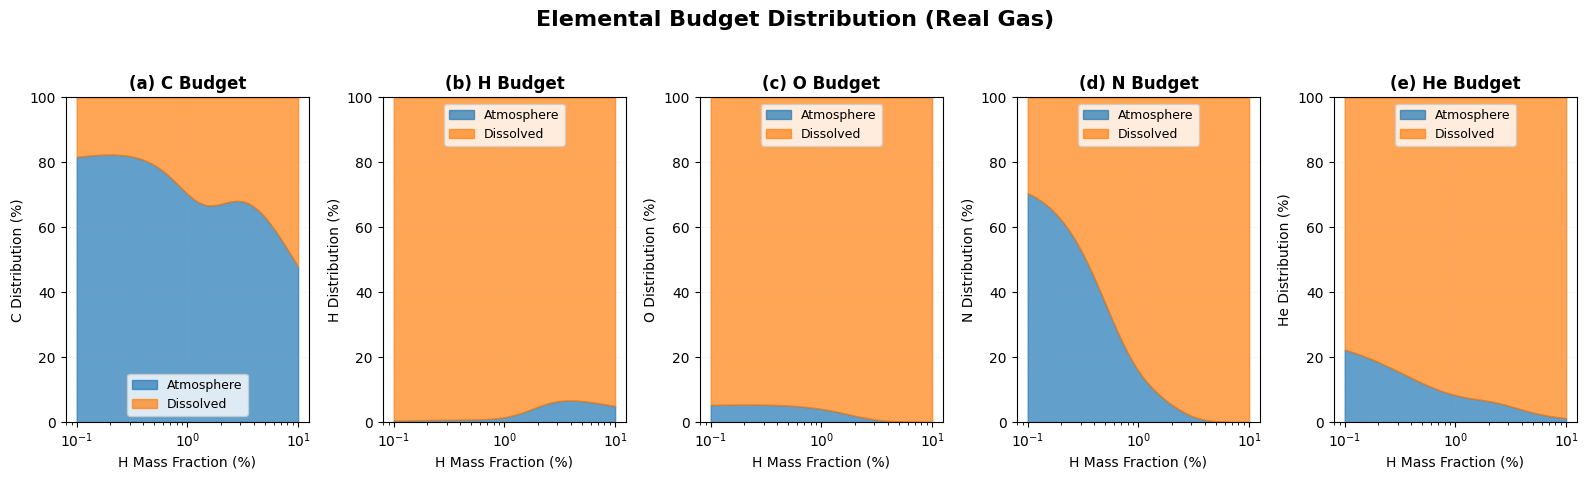


Creating plot for: Elemental Budget Distribution (Ideal Gas)
Reading from: SUBNEPTUNE_IDEALCORT.xlsx

✓ Successfully saved: ABABASIUB.png
Displaying plot for Elemental Budget Distribution (Ideal Gas)...


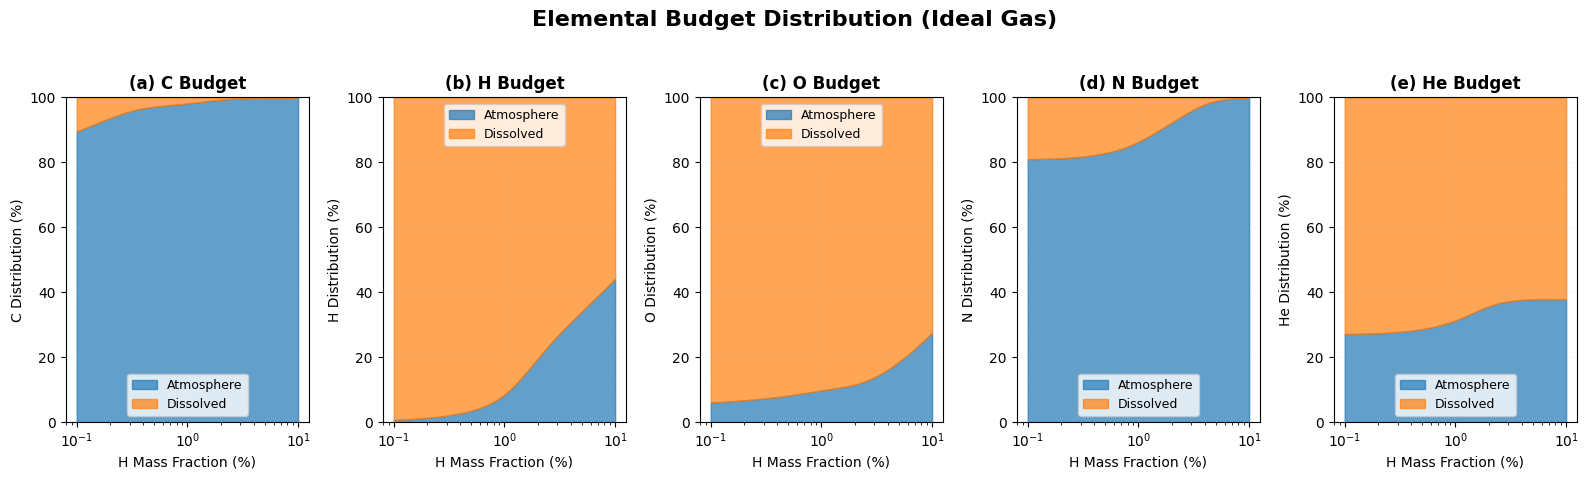


All plotting tasks complete.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_elemental_budget_from_excel_real(excel_file, output_filename, main_title, elements=('C','H','O', 'N', 'He')):
    """
    Plots the elemental budget from a specified Excel file and saves it.

    Args:
        excel_file (str): Path to the input Excel file.
        output_filename (str): Filename for the saved PNG image.
        main_title (str): The main title for the entire figure.
        elements (tuple, optional): The elements to plot. Defaults to ('C','H','O').
    """
    print("\n" + "="*70)
    print(f"Creating plot for: {main_title}")
    print(f"Reading from: {excel_file}")
    print("="*70)

    try:
        df_H = pd.read_excel(excel_file, sheet_name='element_H')
    except Exception as e:
        print(f"Error reading 'element_H' sheet from {excel_file}: {e}")
        print("Please ensure the Excel file path is correct and the sheet exists.")
        raise # Re-raise exception to be caught by the loop's try...except

    if 'atmosphere_ppmw' not in df_H.columns:
        print("Error: Could not find 'atmosphere_ppmw' column in 'element_H' sheet.")
        raise KeyError("Could not find atmosphere_ppmw in element_H sheet.")
        
    df_planet = pd.read_excel(excel_file, sheet_name='planet')
    mass = df_planet['planet_mass']
    H_frac_percent = (df_H['total_mass'] / mass) * 100 # ppmw → %

    fig, axes = plt.subplots(1, len(elements), figsize=(16, 5))

    # --- Set the dynamic overall figure title ---
    fig.suptitle(main_title, fontsize=16, fontweight='bold')
    # --------------------------------------------

    all_sheets_found = True
    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        
        try:
            df = pd.read_excel(excel_file, sheet_name=sheet)
        except Exception as e:
            print(f"Warning: Could not read sheet '{sheet}'. Skipping element {element}.")
            print(f"  Details: {e}")
            ax.set_title(f'({chr(97+idx)}) {element} Budget - Data N/A', fontweight='bold')
            ax.text(0.5, 0.5, f"Data for '{sheet}'\nnot found", 
                    horizontalalignment='center', verticalalignment='center', 
                    transform=ax.transAxes, color='red', fontsize=10)
            all_sheets_found = False
            continue # Skip to the next element if sheet is missing

        # Use .get() with fallback to zeros
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))

        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide by zero

        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100

        # Compute cumulative stacked boundaries
        y1 = atm_frac
        y2 = atm_frac + dis_frac
        y3 = atm_frac + dis_frac + con_frac

        # Clip to [0, 100] so nothing spills out of the plot
        y1, y2, y3 = [np.clip(y, 0, 100) for y in (y1, y2, y3)]

        # Plot stacked areas
        ax.fill_between(H_frac_percent, 0, y1, label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, y1, y2, label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(H_frac_percent, y2, y3, label='Condensed', color='#2ca02c', alpha=0.7)

        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('H Mass Fraction (%)')
        ax.set_ylabel(f'{element} Distribution (%)')
        ax.set_title(f'({chr(97+idx)}) {element} Budget', fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

    # Adjust layout to make room for the suptitle
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) 
    
    # --- Use the dynamic output filename ---
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"\n✓ Successfully saved: {output_filename}")
    # -------------------------------------
    
    # --- Show the plot ---
    print(f"Displaying plot for {main_title}...")
    plt.show()
    # ---------------------

    plt.close(fig) # Close the figure to free up memory before the next loop
    
    if not all_sheets_found:
        print("\nNote: Plot generated, but some element data sheets were missing.")

# --- Main execution loop ---

# Define the cases to plot
plot_cases = [
    {
        "excel_file": "SUBNEPTUNE_REALCORT.xlsx",
        "output_filename": "AASUBA.png",
        "main_title": "Elemental Budget Distribution (Real Gas)"
    },
    {
        "excel_file": "SUBNEPTUNE_IDEALCORT.xlsx",
        "output_filename": "ABABASIUB.png",
        "main_title": "Elemental Budget Distribution (Ideal Gas)"
    }
]

print("\nStarting batch plot generation...")

for case in plot_cases:
    try:
        plot_elemental_budget_from_excel_real(
            excel_file=case["excel_file"],
            output_filename=case["output_filename"],
            main_title=case["main_title"]
            # We use the default elements: ('C', 'H', 'O')
        )
    except Exception as e:
        print(f"\n--- FAILED to plot for: {case['excel_file']} ---")
        print(f"Error: {e}")
        print("Please check file path, sheet names, and data columns.")
        print("--------------------------------------------------\n")

print("\n" + "="*70)
print("All plotting tasks complete.")
print("="*70)



/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_52368/1150428617.py:136: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


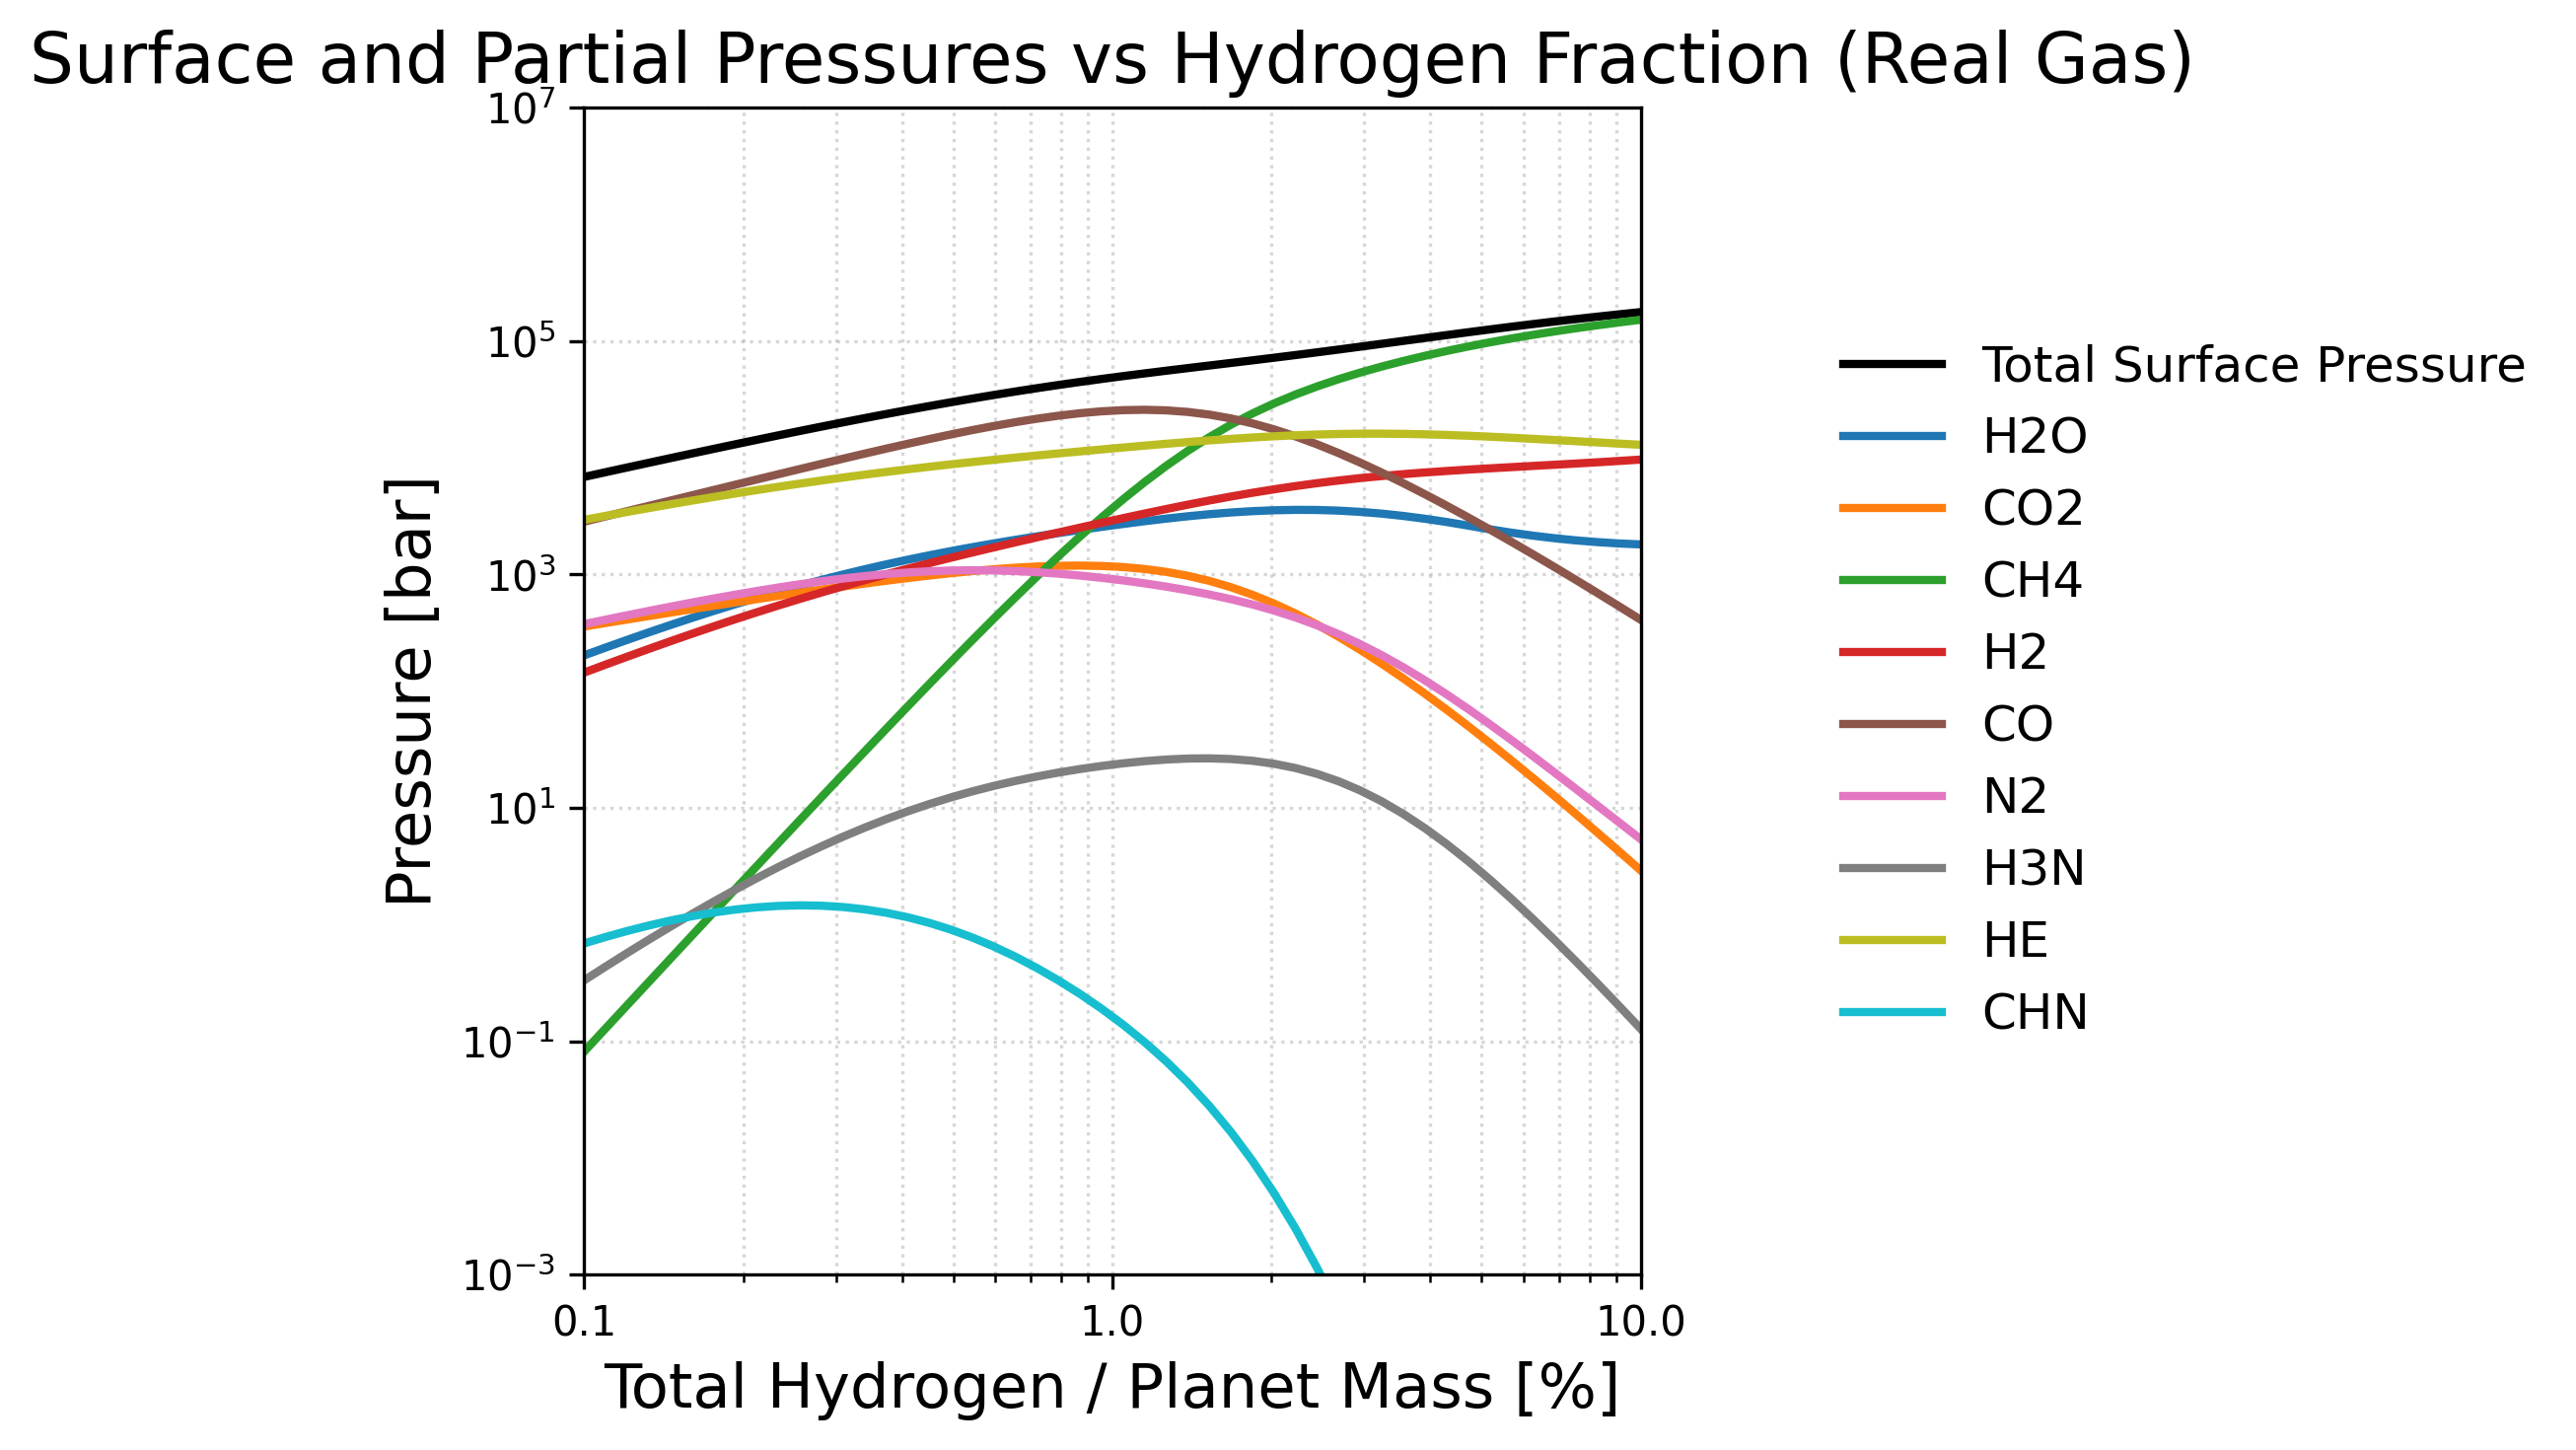

In [15]:
# ===========================================================
# STYLE — SAME AS PARTITIONING PLOTS
# ===========================================================
# ===========================================================
# STYLE (presentation style)
# ===========================================================
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from matplotlib import colormaps
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5
    plt.rcParams["axes.prop_cycle"] = plt.cycler(color=colormaps["tab10"].colors)

# Stronger distinct colors for the 4 H2O/H2 partitioning components
palette = plt.cycler(color=colormaps["tab10"].colors)

# ===========================================================
# PRESSURE PLOT (MATCHING STYLE+LAYOUT)
# ===========================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator

set_style()

excel_file = "SUBNEPTUNE_REALCORT.xlsx"
species = ['H2O_g','CO2_g','CH4_g','H2_g','CO_g','N2_g','H3N_g','He_g','CHN_g']

# Load data
df_H      = pd.read_excel(excel_file, sheet_name='element_H')
df_atm    = pd.read_excel(excel_file, sheet_name='atmosphere')
df_planet = pd.read_excel(excel_file, sheet_name='planet')

mass = df_planet['planet_mass']
x = (df_H['total_mass'] / mass) * 100 # convert to [%] like the partitioning plots
P_surf = df_atm['pressure']

# Colors
colors = plt.get_cmap("tab10")(np.linspace(0, 1, len(species)))


fig, ax = plt.subplots(figsize=(8, 5), dpi=300, layout="constrained")

# -----------------------------------------------------------
# Total surface pressure
# -----------------------------------------------------------
ax.plot(
    x, P_surf,
    color='black', linewidth=2,
    label='Total Surface Pressure'
)

# -----------------------------------------------------------
# Partial pressures
# -----------------------------------------------------------
for i, sp in enumerate(species):
    try:
        df_g = pd.read_excel(excel_file, sheet_name=sp)
        if 'pressure' not in df_g.columns:
            continue

        ax.plot(
            x, df_g['pressure'],
            linestyle='-', linewidth=2,
            color=colors[i],
            label=sp.replace('_g', '').upper()
        )
    except Exception:
        continue

# -----------------------------------------------------------
# AXES — MATCH PARTITIONING FIGURE
# -----------------------------------------------------------
ax.set_xscale("log")
ax.set_yscale("log")

# Use the same x-tick style: fixed decimal ticks
xmin = min(x)
xmax = max(x)
x_ticks = [xmin, 1, xmax]
ax.set_xlim(xmin, xmax)
ax.xaxis.set_major_locator(FixedLocator(x_ticks))

formatter = ScalarFormatter()
formatter.set_scientific(False)
ax.xaxis.set_major_formatter(formatter)

ax.set_ylim(1e-3, 1e7)

ax.set_xlabel(
    "Total Hydrogen / Planet Mass [%]",
)
ax.set_ylabel(
    "Pressure [bar]",
)

# -----------------------------------------------------------
# TITLE
# -----------------------------------------------------------
ax.set_title(
    "Surface and Partial Pressures vs Hydrogen Fraction (Real Gas)"
)

# -----------------------------------------------------------
# GRID — same style
# -----------------------------------------------------------
ax.grid(True, linestyle=':', alpha=0.5, which='both')

# -----------------------------------------------------------
# LEGEND — identical style/position as H2O/H2 plot
# -----------------------------------------------------------
ax.legend(
    frameon=False,
    loc="center left", 
    bbox_to_anchor=(1.15, 0.5)
)

# -----------------------------------------------------------
# FINAL LAYOUT +

plt.tight_layout()
plt.savefig("pressures_presentation.png", dpi=300)
plt.show()


In [151]:
# Vary Linearly:
fO2_log10_shifts = np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(number_of_realisations, 0)  # 1% of planet mass
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
        "H": h_kg,
        "C": h_kg * C_H_RATIO,
        "N": h_kg * N_H_RATIO,
        "He": h_kg * He_H_RATIO
    }

In [120]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_31606/3663148713.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Set2")


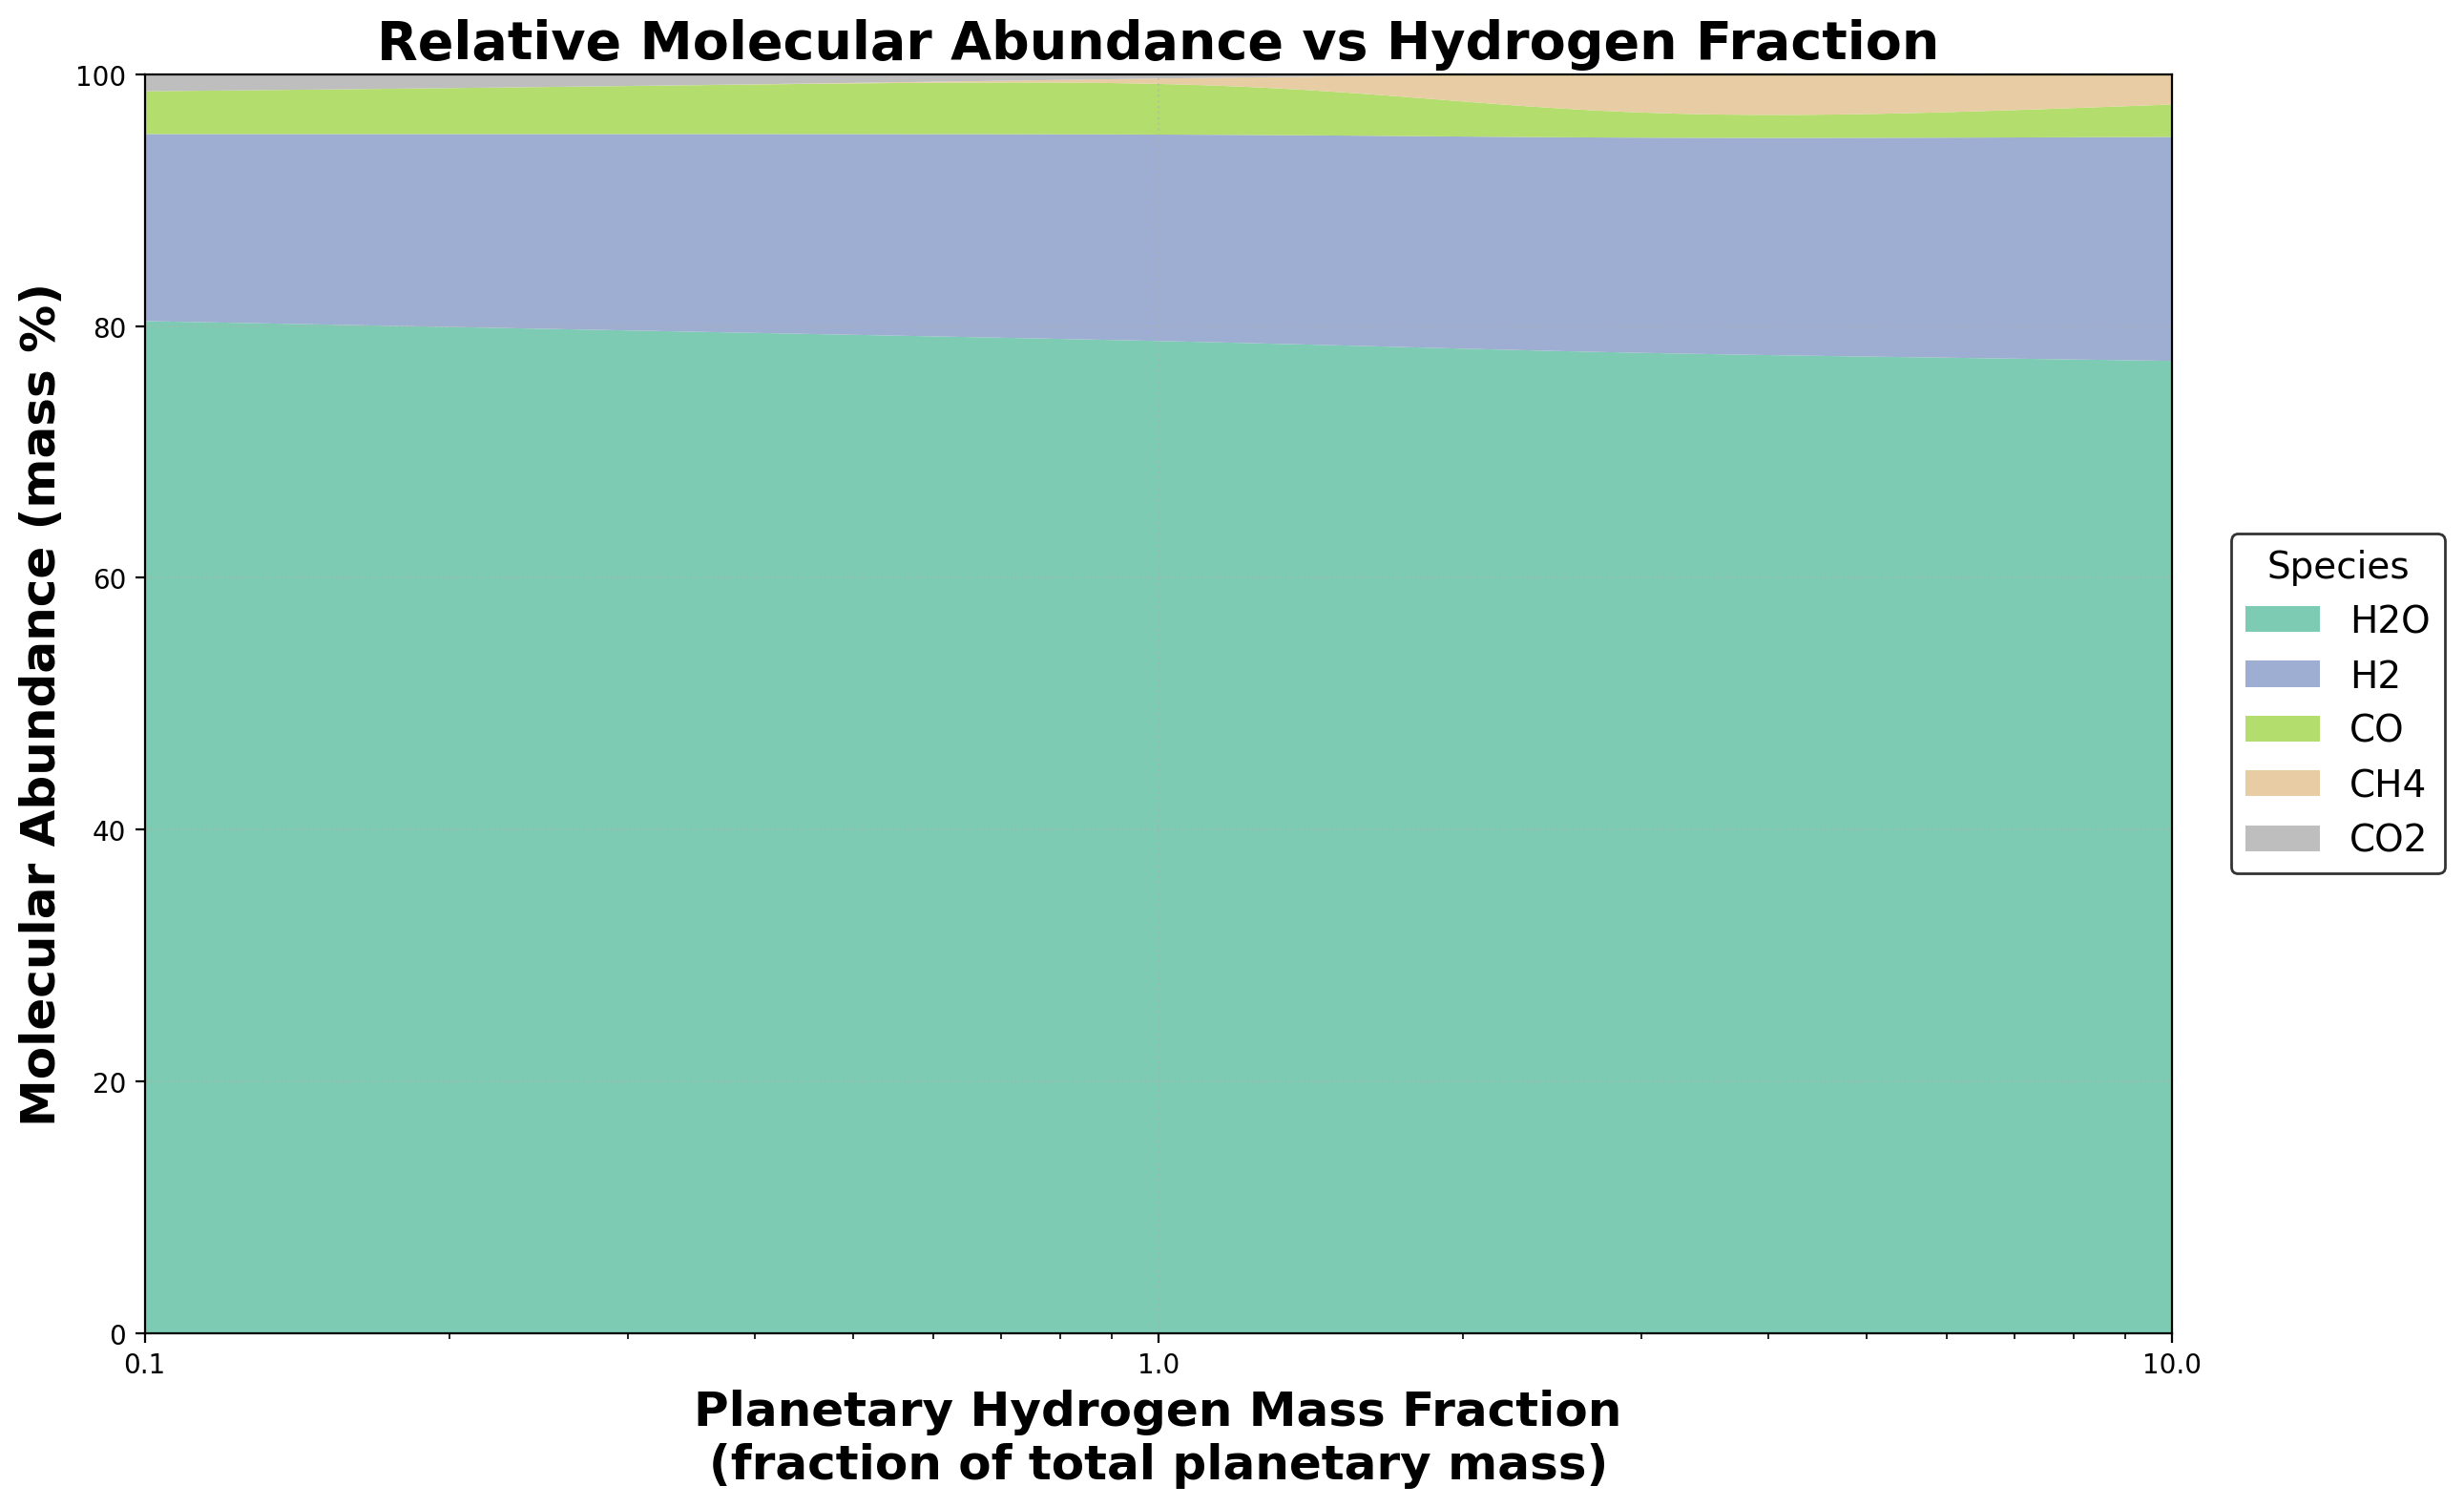

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter

# ===========================================================
# GLOBAL STYLE (matches your other figures)
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 18
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

# ===========================================================
# STACKPLOT FUNCTION
# ===========================================================
def plot_abundance_stackplot(
    excel_file,
    species_sheets,
    outfile="abundance_stackplot.png"
):
    """
    Makes a clean, presentation-ready stackplot of mass percentages
    for any set of species stored in Excel file sheets.

    Parameters
    ----------
    excel_file : str
        Path to Excel file.
    species_sheets : list of str
        Names of sheets containing species mass data.
        Example: ["H2O_g", "H2_g", "CO2_g"]
    """

    set_style()

    # Read planet mass + H content for x-axis
    df_H = pd.read_excel(excel_file, sheet_name="element_H")
    df_planet = pd.read_excel(excel_file, sheet_name="planet")

    planet_mass = df_planet["planet_mass"]
    X = (df_H["total_mass"] / planet_mass) * 100  # hydrogen fraction

    # -------------------------------------------------------
    # Load all species total masses (atm + dissolved + cond)
    # -------------------------------------------------------
    species_data = {}

    for sp in species_sheets:
        df_sp = pd.read_excel(excel_file, sheet_name=sp)

        atm = df_sp["atmosphere_moles"]
        dis = df_sp["dissolved_moles"]
        if "condensed_mass" in df_sp.columns:
            con = df_sp["condensed_moles"]
        else:
            con = 0

        total = atm + dis + con
        species_data[sp.replace("_g", "")] = total

    df_mass = pd.DataFrame(species_data)

    # -------------------------------------------------------
    # Convert to % of total volatile mass
    # -------------------------------------------------------
    total_mass = df_mass.sum(axis=1)
    df_percent = df_mass.div(total_mass, axis=0).fillna(0) * 100

    # Sort species by mean abundance (prettier)
    sorted_cols = df_percent.mean().sort_values(ascending=False).index
    df_percent = df_percent[sorted_cols]

    # -------------------------------------------------------
    # COLORS (use same Set2 palette as your other plots)
    # -------------------------------------------------------
    cmap = get_cmap("Set2")
    colors = cmap(np.linspace(0, 1, df_percent.shape[1]))

    # -------------------------------------------------------
    # PLOT
    # -------------------------------------------------------
    fig, ax = plt.subplots(figsize=(13, 8), dpi=200)

    ax.stackplot(
        X,
        df_percent.values.T,
        labels=df_percent.columns,
        colors=colors,
        alpha=0.85,
        linewidth=0
    )

    # X-axis formatting
    ax.set_xscale("log")
    ax.set_xlim(X.min(), X.max())

    fmt = ScalarFormatter()
    fmt.set_scientific(False)
    ax.xaxis.set_major_formatter(fmt)

    # Labels & title
    ax.set_ylabel("Molecular Abundance (mass %)", fontsize=18, fontweight="bold")
    ax.set_xlabel(
        "Planetary Hydrogen Mass Fraction\n(fraction of total planetary mass)",
        fontsize=18, fontweight="bold"
    )
    ax.set_title(
        "Relative Molecular Abundance vs Hydrogen Fraction",
        fontsize=20, fontweight="bold"
    )

    ax.set_ylim(0, 100)
    ax.grid(True, linestyle=":", alpha=0.45)

    # Legend
    ax.legend(
        title="Species",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=14,
        title_fontsize=14,
        frameon=True,
        facecolor="white",
        edgecolor="black"
    )

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()


# ===========================================================
# EXAMPLE USE
# ===========================================================

# Which species to import (sheet names)
species_sheets = [
    "H2O_g",
    "H2_g",
    "CO2_g",
    "CH4_g",
    "CO_g",
]

# Call the function
plot_abundance_stackplot(
    excel_file="SUBNEPTUNE_REALCORTT.xlsx",
    species_sheets=species_sheets,
    outfile="molecular_abundance_stackplotTT.png"
)
